# Ordering a Mock Stream with the MST Backbone


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/GalacticDynamics/phasecurvefit/blob/main/docs/tutorials/stream_mst.ipynb)


Here we order a mock stellar stream with the `MSTOrderer`. A tidal stream's velocity field points outward from the progenitor along **both** arms -- it reverses at the progenitor. The local-flow walk in the [stream autoencoder tutorial](stream_autoencoder.ipynb) handles this by starting at the progenitor and walking both ways, which means knowing where the progenitor is. The MST needs no progenitor and no start index: it links each star to its near neighbours, keeps the minimum spanning tree of those links, and orders the stars along the tree's longest path, which runs from one tip of the stream to the other.

We also scatter in a handful of interlopers and reject them two complementary ways: the MST's own `edge_clip_sigma` removes the spatially-isolated ones at the orderer, and the mixture-model membership catches the rest, near the track.

The data are the same simulated stream as the [stream autoencoder tutorial](stream_autoencoder.ipynb), which describes the simulation.

In [1]:
import pathlib
import pickle

import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import cKDTree

import quaxed.numpy as jnp
import unxt as u

import phasecurvefit as pcf

In [2]:
key = jr.key(201030)
usys = u.unitsystems.galactic

## Data: a mock stream

Loads the simulated stream cached in `mockstream.pkl` by the other stream tutorials. (Unpickling it needs `galax` installed.)


In [3]:
mockstream_path = pathlib.Path("mockstream.pkl")
with mockstream_path.open("rb") as handle:
    mockstream, prog = pickle.load(handle)  # noqa: S301

## Interlopers

A real ordering never gets a clean catalogue. We scatter 30 field stars across the footprint with velocities uncorrelated with the stream. The MST has no reject option, so it threads them into the ordering along their cheapest edge -- exactly the failure the mixture model is built to catch.

In [4]:
comps = mockstream.q.components
qs0 = {c: getattr(mockstream.q, c) for c in comps}
ps0 = {c: getattr(mockstream.p, c) for c in comps}
n_star = len(qs0["x"])

# 30 interlopers: uniform over the position footprint, random velocities.
N_OUT = 30
okey = jr.key(777)
lo = {c: float(u.ustrip(usys, qs0[c]).min()) for c in comps}
hi = {c: float(u.ustrip(usys, qs0[c]).max()) for c in comps}
q_out, p_out = {}, {}
for i, c in enumerate(comps):
    kq, kp = jr.split(jr.fold_in(okey, i))
    q_out[c] = u.Quantity(jr.uniform(kq, (N_OUT,), minval=lo[c], maxval=hi[c]), "kpc")
    p_out[c] = u.Quantity(0.12 * jr.normal(kp, (N_OUT,)), "kpc/Myr")

qs_all = {c: jnp.concatenate([qs0[c], q_out[c]]) for c in comps}
ps_all = {c: jnp.concatenate([ps0[c], p_out[c]]) for c in comps}
is_outlier = jnp.concatenate(
    [jnp.zeros(n_star, dtype=bool), jnp.ones(N_OUT, dtype=bool)]
)
print(f"{n_star} stream stars + {N_OUT} interlopers")

8000 stream stars + 30 interlopers


In [5]:
# Shuffle; no start index or progenitor is needed for the MST.
key, subkey = jr.split(key)
order = jr.permutation(subkey, jnp.arange(n_star + N_OUT))
qs = {c: qs_all[c][order] for c in comps}
ps = {c: ps_all[c][order] for c in comps}
is_outlier = is_outlier[order]

## MST ordering

`jump_cap` is the longest link the tree may use. We set it from the data: the 99.98th percentile of the stars' nearest-neighbour distances. The percentile is high because the stream's density varies a lot: the sparse tips have genuinely large gaps between stars, and the cap must keep them connected while still cutting any longer jump. `k=16` is the number of neighbours each star is linked to before the tree is built. Real streams occasionally leave a stray point disconnected, so we keep the largest component (`on_disconnected="largest"`). No progenitor or start index is needed; `orient_by_velocity` gives `gamma` a physical direction.


In [6]:
comps = list(qs)
P = np.stack([np.asarray(u.ustrip(usys, qs[c])) for c in comps], axis=1)
nn = cKDTree(P).query(P, k=2)[0][:, 1]
jump_cap = float(np.percentile(nn, 99.98))

orderer = pcf.orderers.MSTOrderer(
    k=16,
    jump_cap=jump_cap,
    orient_by_velocity=True,
    on_disconnected="largest",
)
mstresult = orderer.order(qs, ps, metadata=pcf.StateMetadata(usys=usys))
print("coverage:", int((mstresult.indices >= 0).sum()), "/", len(is_outlier))

coverage: 8028 / 8030


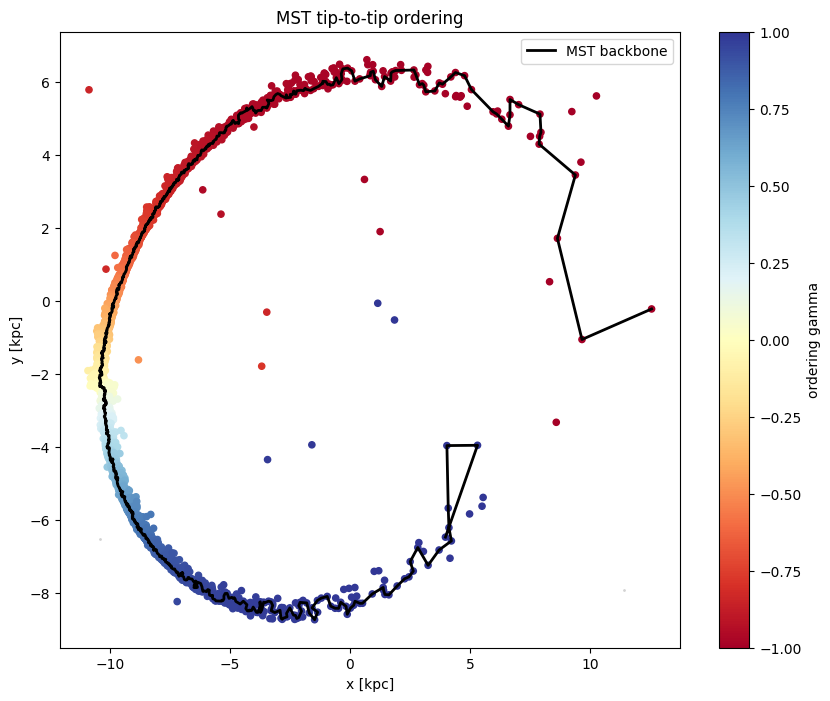

In [7]:
_fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(qs["x"], qs["y"], s=1, c="lightgray")
oq = {k: v[mstresult.ordering] for k, v in mstresult.positions.items()}
timeline = np.linspace(-1, 1, len(mstresult.ordering))
im = ax.scatter(oq["x"], oq["y"], s=20, c=timeline, cmap="RdYlBu")
bx = mstresult.backbone
ax.plot(np.asarray(bx["x"]), np.asarray(bx["y"]), c="k", lw=2, label="MST backbone")
plt.colorbar(im, ax=ax, label="ordering gamma")
ax.set(xlabel="x [kpc]", ylabel="y [kpc]", title="MST tip-to-tip ordering")
ax.legend()
plt.show()

**What to look for:** the colour should run smoothly from one tip to the other, with the black backbone (the tree's longest path) along the middle of the stream. Note that the interlopers are coloured too: the MST has given every one of them a place in the ordering.

## Rejecting interlopers at the orderer

The MST threaded the 30 interlopers in, but most are *spatially isolated* -- tied to the backbone by a single long edge. `edge_clip_sigma` robustly sigma-clips those edge lengths (in log space, keeping a continuous sparse tail) and leaves the isolated points unvisited before the autoencoder ever sees them. It is the cheap, geometric complement to the posterior membership below: clipping removes the obvious strays; the few that blend in near the track are left for the membership model.

In [8]:
clipped = pcf.orderers.MSTOrderer(
    k=16,
    jump_cap=jump_cap,
    orient_by_velocity=True,
    on_disconnected="largest",
    edge_clip_sigma=8.0,  # reject outliers by MST edge length
).order(qs, ps, metadata=pcf.StateMetadata(usys=usys))

o = np.asarray(is_outlier)
kept = np.zeros(len(o), dtype=bool)
idx = np.asarray(clipped.indices)
kept[idx[idx >= 0]] = True
print(f"interlopers rejected: {int((o & ~kept).sum())}/{int(o.sum())}")
print(f"genuine stars cut   : {int((~o & ~kept).sum())}/{int((~o).sum())}")

interlopers rejected: 27/30
genuine stars cut   : 3/8000


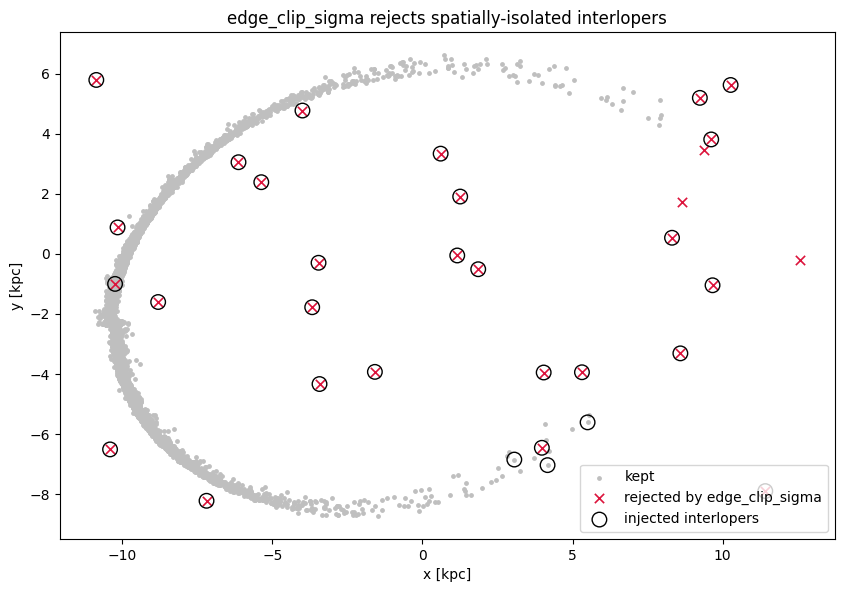

In [9]:
_fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(
    np.asarray(qs["x"])[kept], np.asarray(qs["y"])[kept], s=6, c="0.75", label="kept"
)
ax.scatter(
    np.asarray(qs["x"])[~kept],
    np.asarray(qs["y"])[~kept],
    s=45,
    c="crimson",
    marker="x",
    lw=1.2,
    label="rejected by edge_clip_sigma",
)
ax.scatter(
    np.asarray(qs["x"])[o],
    np.asarray(qs["y"])[o],
    s=110,
    facecolors="none",
    edgecolors="k",
    lw=1.0,
    label="injected interlopers",
)
ax.set(
    xlabel="x [kpc]",
    ylabel="y [kpc]",
    title="edge_clip_sigma rejects spatially-isolated interlopers",
    aspect="equal",
)
ax.legend()
plt.show()

## Autoencoder mean path

The MST's ordering feeds the autoencoder exactly as the walk's did in the [stream autoencoder tutorial](stream_autoencoder.ipynb). The difference here is `MixtureMembershipConfig`, which switches membership to the stream-plus-background mixture model of the [outlier rejection tutorial](outlier_rejection.ipynb). It applies in the joint training phase, once a track exists to measure distances from.

`sigma_init` and `sigma_ceiling` are in the *normalised* coordinates the model trains in (roughly, units of the data's standard deviation), not in kpc. The width ceiling starts loose and anneals down to 0.3, and `warmup_frac=0.4` ramps the membership term in over the first 40% of the phase, so the track settles before membership can reject much.

In [10]:
key, model_key, train_key = jr.split(key, 3)
normalizer = pcf.nn.StandardScalerNormalizer(qs, ps)
model = pcf.nn.PathAutoencoder.make(
    normalizer, gamma_range=mstresult.gamma_range, key=model_key
)

# Opt in to mixture-model membership (Hogg, Bovy & Lang 2010). The encoder's
# membership becomes a calibrated *posterior* driven by the reconstruction
# residual, so the interlopers the MST threaded in get rejected. See the
# outlier-rejection tutorial and the outlier-rejection guide.
# `membership=None` (the default) recovers the plain classifier behaviour.
membership = pcf.nn.MixtureMembershipConfig(
    sigma_init=0.3,  # guess at the stream half-width (normalised units)
    sigma_ceiling=(1.0, 0.3),  # anneal the width ceiling down
    warmup_frac=0.4,  # fit the track before rejecting anything
)
config = pcf.nn.TrainingConfig(membership=membership)
result, _, losses = pcf.nn.train_autoencoder(
    model, mstresult, config=config, key=train_key
)

Training:   0%|          | 0/800 [00:00<?, ?epoch/s]

Training:   0%|          | 0/100 [00:00<?, ?epoch/s]

Training:   0%|          | 0/200 [00:00<?, ?epoch/s]

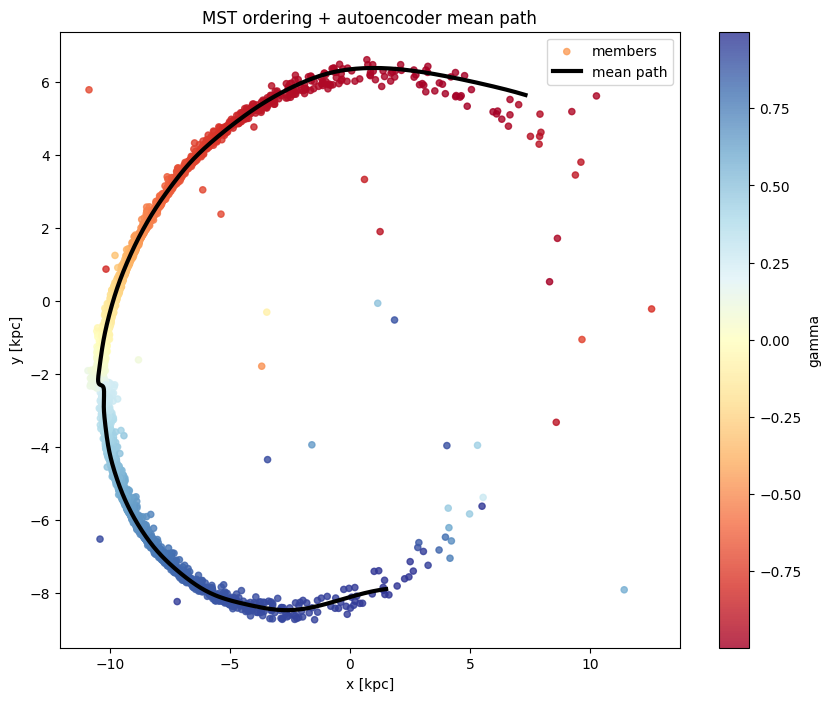

In [11]:
_fig, ax = plt.subplots(figsize=(10, 8))
all_gamma, all_probs = result.model.encode(mstresult.positions, mstresult.velocities)
qs_pred = result(jnp.linspace(*result.gamma_range, 1_000))
im = ax.scatter(
    np.asarray(qs["x"]),
    np.asarray(qs["y"]),
    s=20,
    c=np.asarray(all_gamma),
    cmap="RdYlBu",
    alpha=0.8,
    label="members",
)
ax.plot(
    np.asarray(qs_pred["x"]), np.asarray(qs_pred["y"]), c="k", lw=3, label="mean path"
)
plt.colorbar(im, ax=ax, label="gamma")
ax.set(xlabel="x [kpc]", ylabel="y [kpc]", title="MST ordering + autoencoder mean path")
ax.legend()
plt.show()

## Posterior membership

Because we trained with `MixtureMembershipConfig`, the encoder's membership is a calibrated **posterior**: `posterior_membership` folds the encoder's prior together with how far each star landed from the fitted track. The interlopers -- far from the track -- get a low posterior; the stream keeps a high one. Pass `ws` in the same normalised frame used for training.

A few genuine stars at the sparse, fanned-out tips also dip below 0.5: the tidal tail is genuinely diffuse there, so under a single stream width they sit at the boundary. That is why Hogg et al. recommend keeping the posterior as a *weight* rather than a hard threshold.

In [12]:
# posterior_membership expects ws in the normalised training frame.
qn, pn = result.model.normalizer.transform(qs, ps)
ws = jnp.concatenate([qn, pn], axis=1)
membership_prob = pcf.nn.posterior_membership(result.model, ws)

o = np.asarray(is_outlier)
caught = int((membership_prob[o] < 0.5).sum())
kept = int((membership_prob[~o] >= 0.5).sum())
print(f"interlopers rejected (posterior < 0.5) : {caught}/{int(o.sum())}")
print(f"stream stars kept     (posterior >= 0.5): {kept}/{int((~o).sum())}")

interlopers rejected (posterior < 0.5) : 30/30
stream stars kept     (posterior >= 0.5): 7711/8000


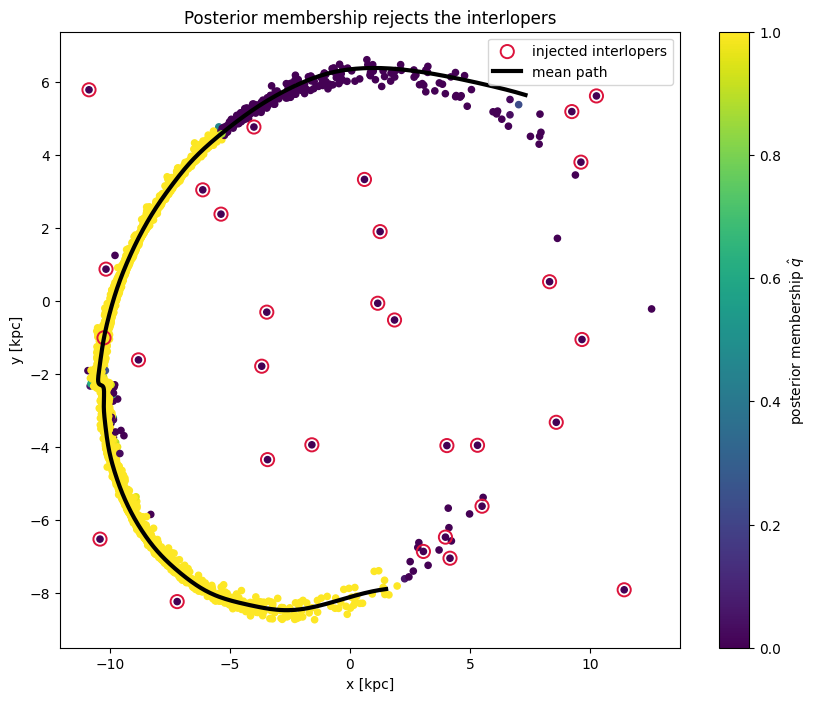

In [13]:
_fig, ax = plt.subplots(figsize=(10, 8))
o = np.asarray(is_outlier)
sc = ax.scatter(
    np.asarray(qs["x"]),
    np.asarray(qs["y"]),
    s=20,
    c=np.asarray(membership_prob),
    cmap="viridis",
    vmin=0,
    vmax=1,
)
ax.scatter(
    np.asarray(qs["x"])[o],
    np.asarray(qs["y"])[o],
    s=90,
    facecolors="none",
    edgecolors="crimson",
    lw=1.4,
    label="injected interlopers",
)
ax.plot(
    np.asarray(qs_pred["x"]), np.asarray(qs_pred["y"]), c="k", lw=3, label="mean path"
)
plt.colorbar(sc, ax=ax, label=r"posterior membership $\hat{q}$")
ax.set(
    xlabel="x [kpc]",
    ylabel="y [kpc]",
    title="Posterior membership rejects the interlopers",
)
ax.legend()
plt.show()

**What to look for:** all 30 interlopers are dark (low posterior), while the stream stays bright. The 52 genuine stars that also fall below 0.5 sit mostly at the diffuse tips, with a few near the progenitor, where the stream is broader than a single width allows.

## Takeaways

- The `MSTOrderer` orders a stream tip to tip with no progenitor or start index.
- It has no reject option, so interlopers get an ordering too. `edge_clip_sigma` removes the spatially isolated ones cheaply at the orderer.
- Mixture-model membership catches the rest, and `posterior_membership` gives the number to use, ideally as a weight rather than a hard cut.

**See also:** the [epitrochoid MST tutorial](epitrochoid_mst.ipynb), for a curve that crosses itself and needs the MST to use velocities.